# Covariance Matrix Adaptation Evolution Strategy (CMA-ES) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

This method uses pycma's active, full-covariance CMA-ES in normalized log-gain coordinates.

1. Evaluate 64 shared stratified initial candidates, including the original controller.
2. Initialize the search mean at the best initial point with sigma0=0.25.
3. Ask the library for a population of 64 samples, mapped into [0, 1] using BoundTransform.
4. Evaluate candidates and tell the library their fitness values; update the mean, covariance, and global step size.
5. Record sigma, covariance eigenvalues, and axis ratio, and retain the best point across all evaluations.
6. Complete 50 updates in the original study. Library stop flags are recorded rather than used to shorten this fixed experiment.

The full covariance learns correlations between controller gains. Active covariance updates use information from poorer samples as well as successful ones. The separate benchmark instead stops at the exact unique-evaluation budget.

Read [cmaes.py](../all%20work/pid%20using%20cma%20es/cmaes.py) for the implemented update rules, [config.json](../all%20work/pid%20using%20cma%20es/config.json) for settings, and [study.py](../all%20work/pid%20using%20cma%20es/study.py) for objective evaluation.


In [2]:
METHOD='CMA-ES'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,Equation-based CMA-ES tuning of AttitudeControl_Sim
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2])


"""Bounded active CMA-ES using pycma, with deterministic evaluation accounting."""
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import json,time
import cma
import numpy as np
from model import baseline
from study import decode,encode,evaluate,write_csv

def distribution_state(es,dimension):
    matrix=es.sm.covariance_matrix
    matrix=np.eye(dimension) if matrix is None else np.asarray(matrix,dtype=float)
    scales=np.broadcast_to(np.asarray(es.sigma_vec.scaling,dtype=float),(dimension,))
    covariance=scales[:,None]*matrix*scales[None,:]
    eigenvalues=np.linalg.eigvalsh(covariance)
    if not np.all(np.isfinite(covariance)) or eigenvalues.min()<=0 or not np.isfinite(es.sigma) or es.sigma<=0:
        raise FloatingPointError('Invalid CMA distribution')
    return {'genotype_mean':es.mean.tolist(),'sigma':float(es.sigma),'covariance':covariance.tolist(),
            'covariance_eigenvalues':eigenvalues.tolist(),'axis_ratio':float(np.sqrt(eigenvalues.max()/eigenvalues.min()))}

def cma_es(cfg,scenarios,seed,outdir,initial=None,label='main',objective=None):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    n=int(cfg['swarm_size']); d=len(cfg['parameters'])
    if n<4 or cfg['iterations']<1 or not 0<cfg['sigma0']<=1: raise ValueError('Invalid population, updates or sigma0')
    rng=np.random.default_rng(seed); x=rng.random((n,d))
    for j in range(d): x[:,j]=(rng.permutation(n)+rng.random(n))/n
    x[0]=encode(baseline(cfg['controller_dt_s']),cfg)
    if initial is not None: x[1]=encode(np.asarray(initial),cfg)
    names=[p['name'] for p in cfg['parameters']]
    archive=x[0].copy(); best=float('inf'); cache={}; history=[]; rows=[]; evaluations=[]; distributions=[]
    start=time.perf_counter(); proposals=0; iteration=0
    def raw_score(unit):
        gains=decode(unit,cfg); f=objective(gains) if objective is not None else evaluate(gains,scenarios,cfg)
        return float(f) if np.isfinite(f) else 1e12
    first_value=raw_score(x[0]); first_key=tuple(np.round(x[0],13))
    with ThreadPoolExecutor(max_workers=cfg['workers']) as pool:
        def evaluate_points(points):
            nonlocal archive,best,proposals,first_value
            proposals+=len(points); keys=[tuple(np.round(p,13)) for p in points]; new={}
            for key,p in zip(keys,points):
                if key not in cache and key not in new: new[key]=p.copy()
            items=list(new.items()); todo=[]; scores={}
            for key,p in items:
                if first_value is not None and key==first_key: scores[key]=first_value; first_value=None
                else: todo.append((key,p))
            for (key,p),f in zip(todo,pool.map(raw_score,[p for _,p in todo])): scores[key]=f
            for key,p in items:
                f=scores[key]; cache[key]=f
                if f<best: best=f; archive=p.copy()
                evaluations.append({'evaluation':len(cache),'iteration':iteration,'fitness':f,'best_so_far':best,**dict(zip(names,decode(p,cfg)))})
            return np.array([cache[key] for key in keys])
        values=evaluate_points(x)
        local_normal=np.random.RandomState(seed).randn
        options={'popsize':n,'bounds':[0.,1.],'BoundaryHandler':cma.BoundTransform,
                 'CMA_active':bool(cfg['cma_active']),'CMA_diagonal':bool(cfg['cma_diagonal']),
                 'seed':seed,'randn':local_normal,'verbose':-9,'verb_log':0,'verb_disp':0}
        es=cma.CMAEvolutionStrategy(x[np.argmin(values)].tolist(),cfg['sigma0'],options)
        for iteration in range(cfg['iterations']+1):
            if iteration:
                samples=es.ask(); x=np.asarray(samples)
                if np.any(x<0) or np.any(x>1): raise AssertionError('Pycma returned out-of-bound phenotype')
                values=evaluate_points(x); es.tell(samples,values.tolist())
            state=distribution_state(es,d); state['iteration']=iteration
            state['library_stop_flags']={str(k):str(v) for k,v in es.sto

## Original three-seed study
These iteration-based results are separate from the strict-budget benchmark below. Unique evaluation counts differ across methods.


In [4]:
original_runs=[load_json(FOLDER/f'results/run_main_{seed}.json') for seed in [11,29,47]]
show_table(original_runs,['seed','fitness','unique_evaluations','seconds'])
show_table([{'gain':k,'value':v} for k,v in load_json(FOLDER/'results/best_gains.json')['gains'].items()])


seed,fitness,unique_evaluations,seconds
11,0.053226156163098386,3264,52.64551639999263
29,0.05367722890441599,3264,51.992270999995526
47,0.05226415044430983,3264,19.49431670003105


gain,value
roll_outer_K,15.92718041983634
roll_inner_Kp_equivalent,0.15782826477321826
roll_inner_Ki_equivalent,0.0028898109968422546
pitch_outer_K,16.219622306251395
pitch_inner_Kp_equivalent,0.16060490633818308
pitch_inner_Ki_equivalent,0.0004147566147601958
yaw_Kp,0.38840111279229916
yaw_Ki,0.09167659154073728


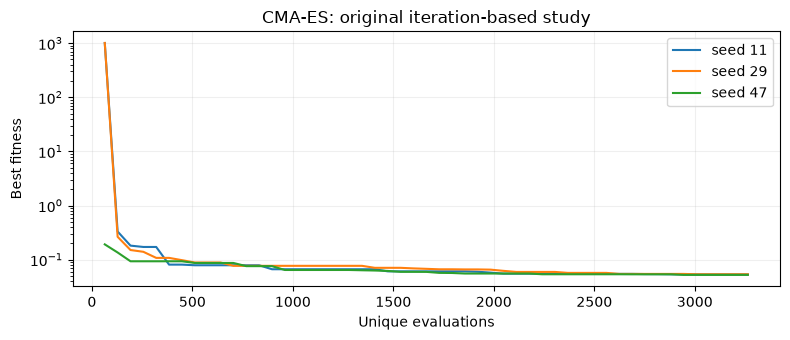

In [5]:
fig,ax=plt.subplots(figsize=(8,3.5))
for record in original_runs:
    history=record['history']
    ax.plot([h['unique_evaluations'] for h in history],[h['best'] for h in history],label=f"seed {record['seed']}")
ax.set(xlabel='Unique evaluations',ylabel='Best fitness',yscale='log',title=f'{METHOD}: original iteration-based study')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
CMA-ES,nominal,30,0.05226415044430983,0.052958784530325265,0.053037539135384566,0.0005636200006585569,30
CMA-ES,robust,30,0.06540049914089047,0.06669607516221868,0.06679798006541089,0.0011446261578759687,30


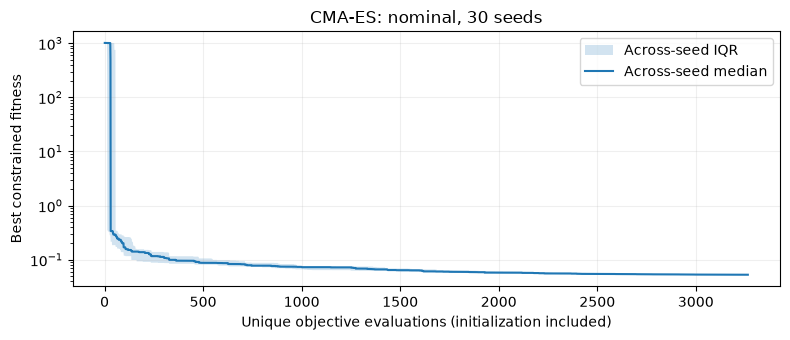

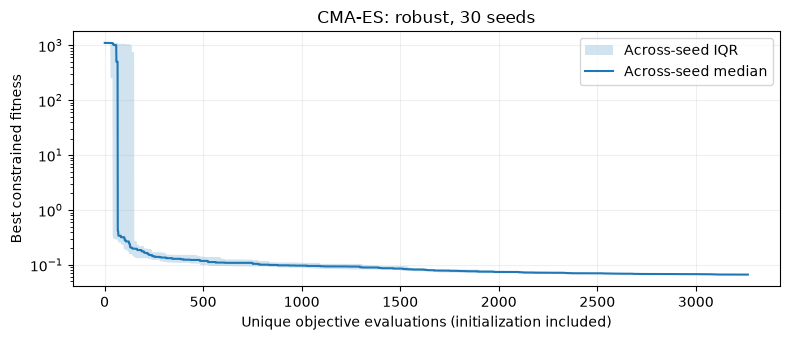

In [6]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [7]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
CMA-ES,nominal,Random single-axis,300,293,298.0,300
CMA-ES,nominal,One-factor boundaries,54,49,50.0,51
CMA-ES,nominal,Combined-axis stress,90,0,0.0,0
CMA-ES,robust,Random single-axis,300,300,300.0,300
CMA-ES,robust,One-factor boundaries,54,53,53.0,54
CMA-ES,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**all work/pid using cma es/results/plots/01_step_responses.png**

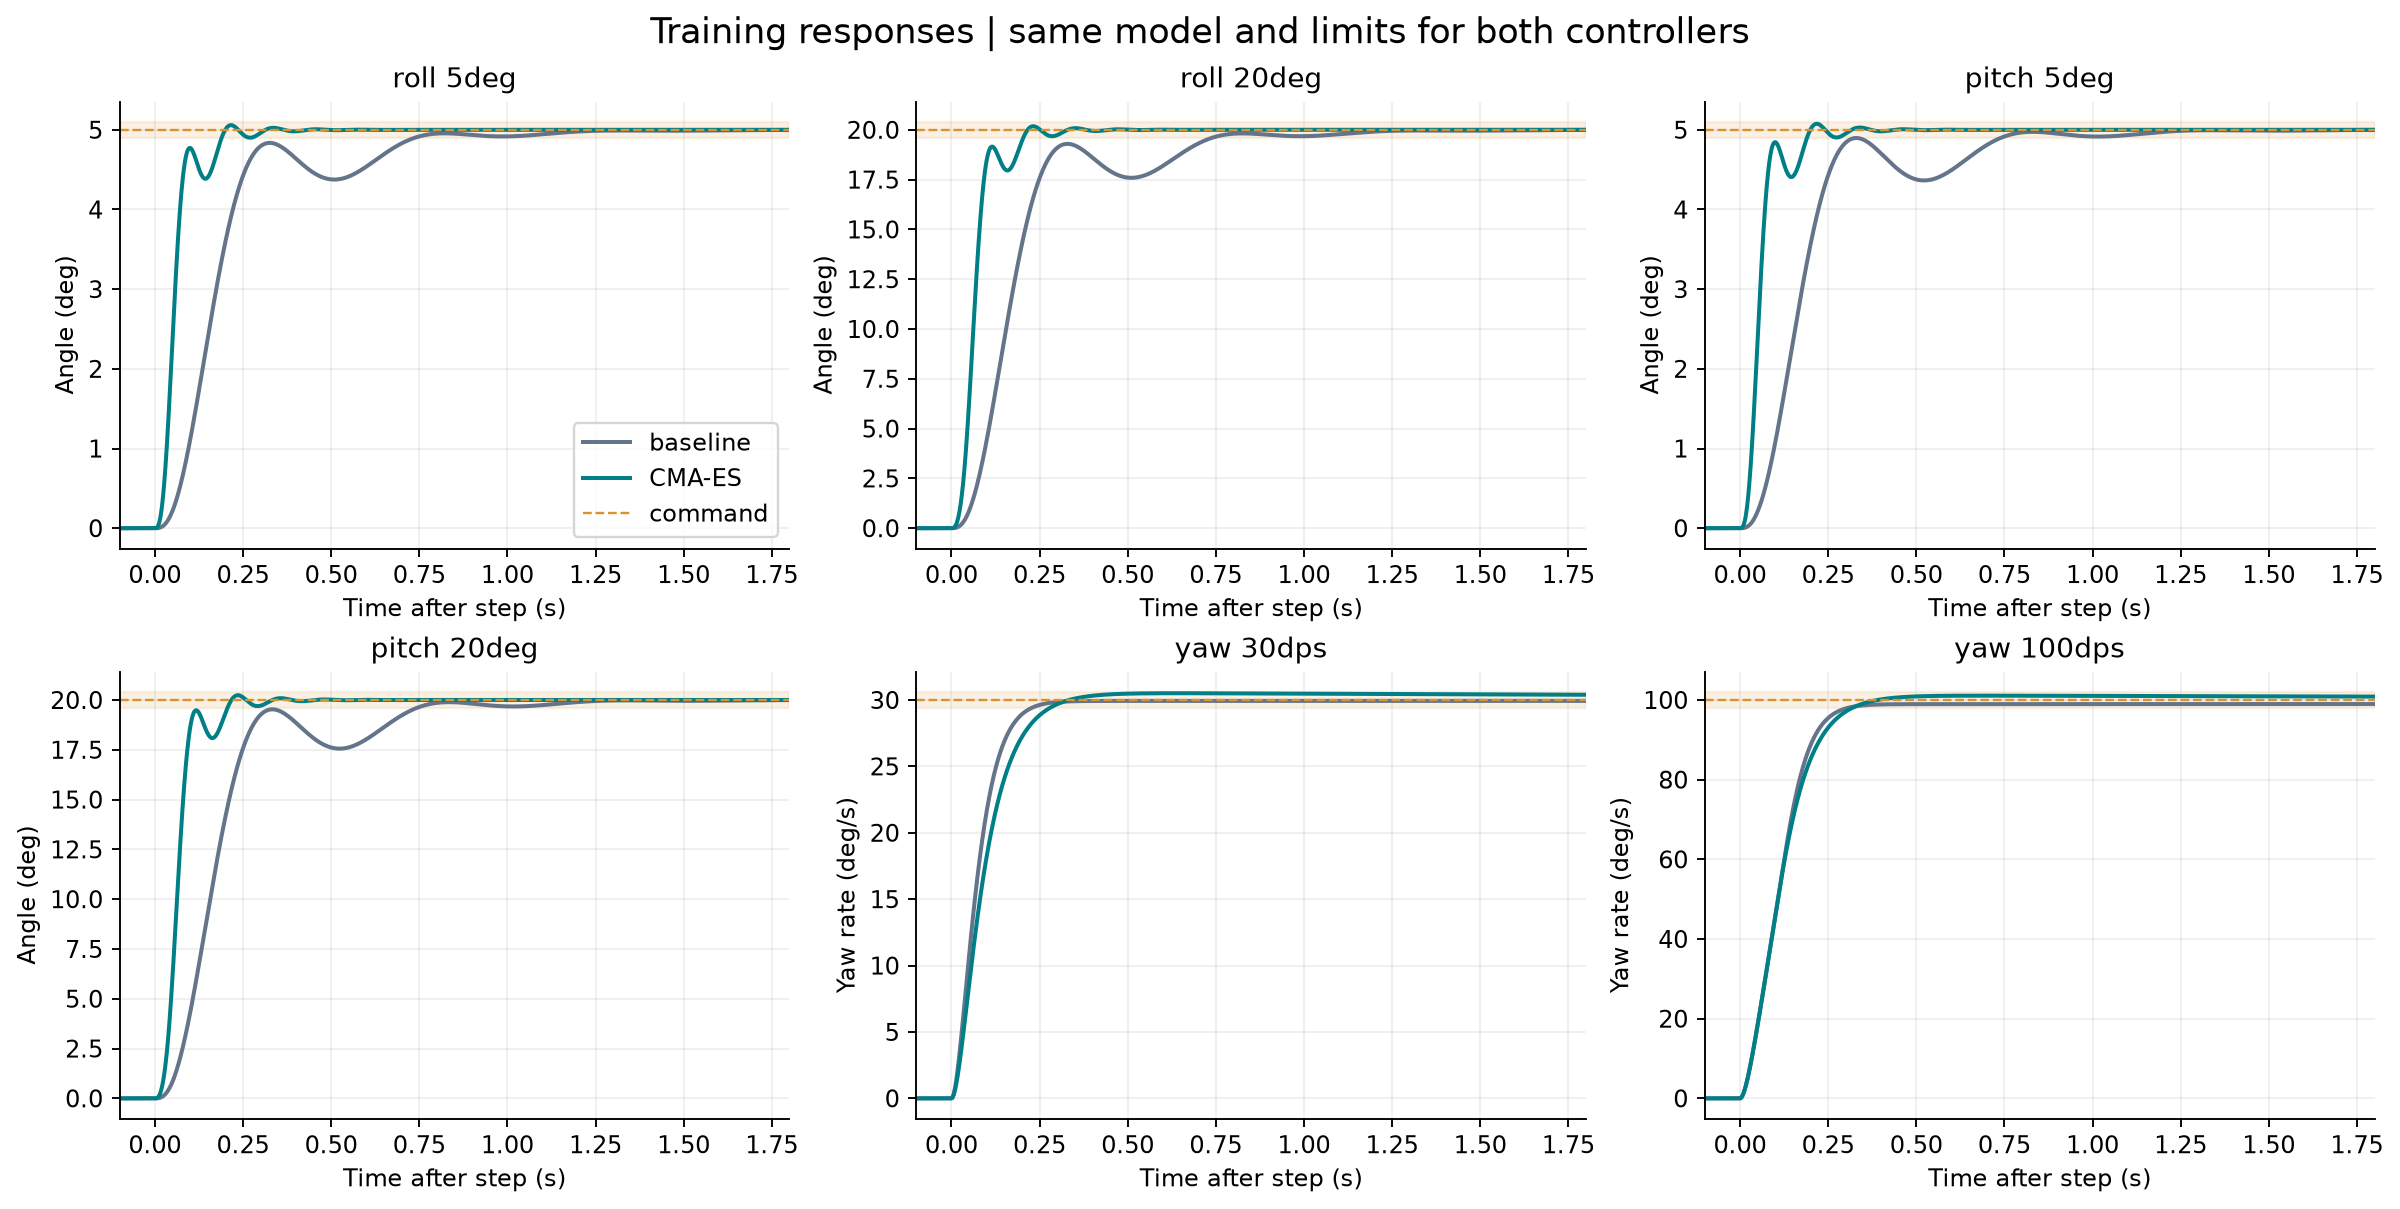

**all work/pid using cma es/results/plots/02_cmaes_iterations.png**

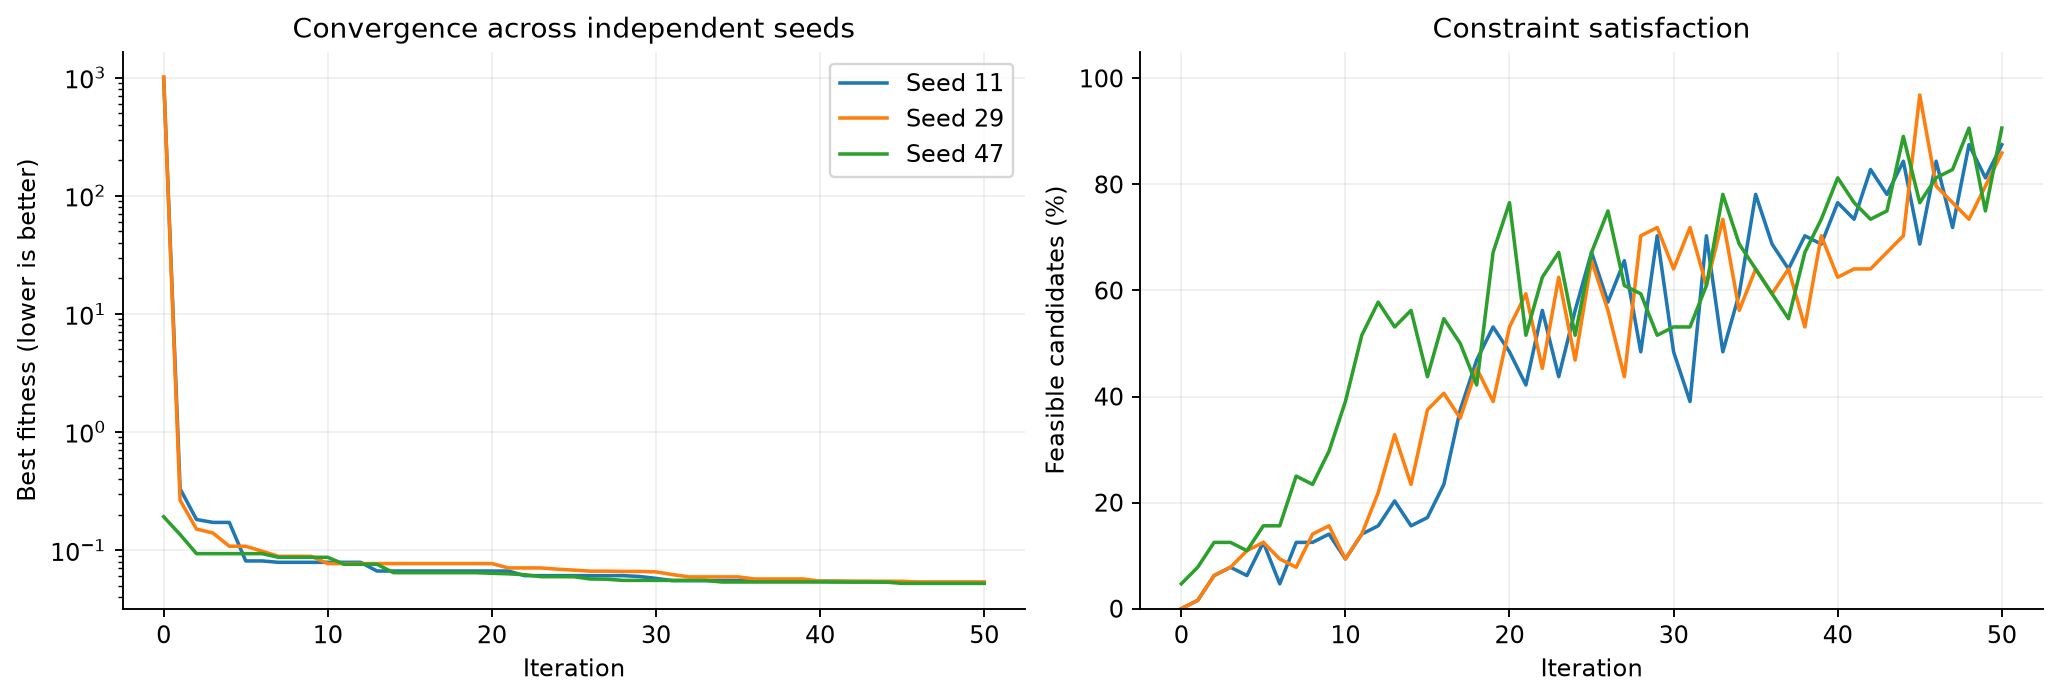

**all work/pid using cma es/results/plots/03_coupled_and_saturation.png**

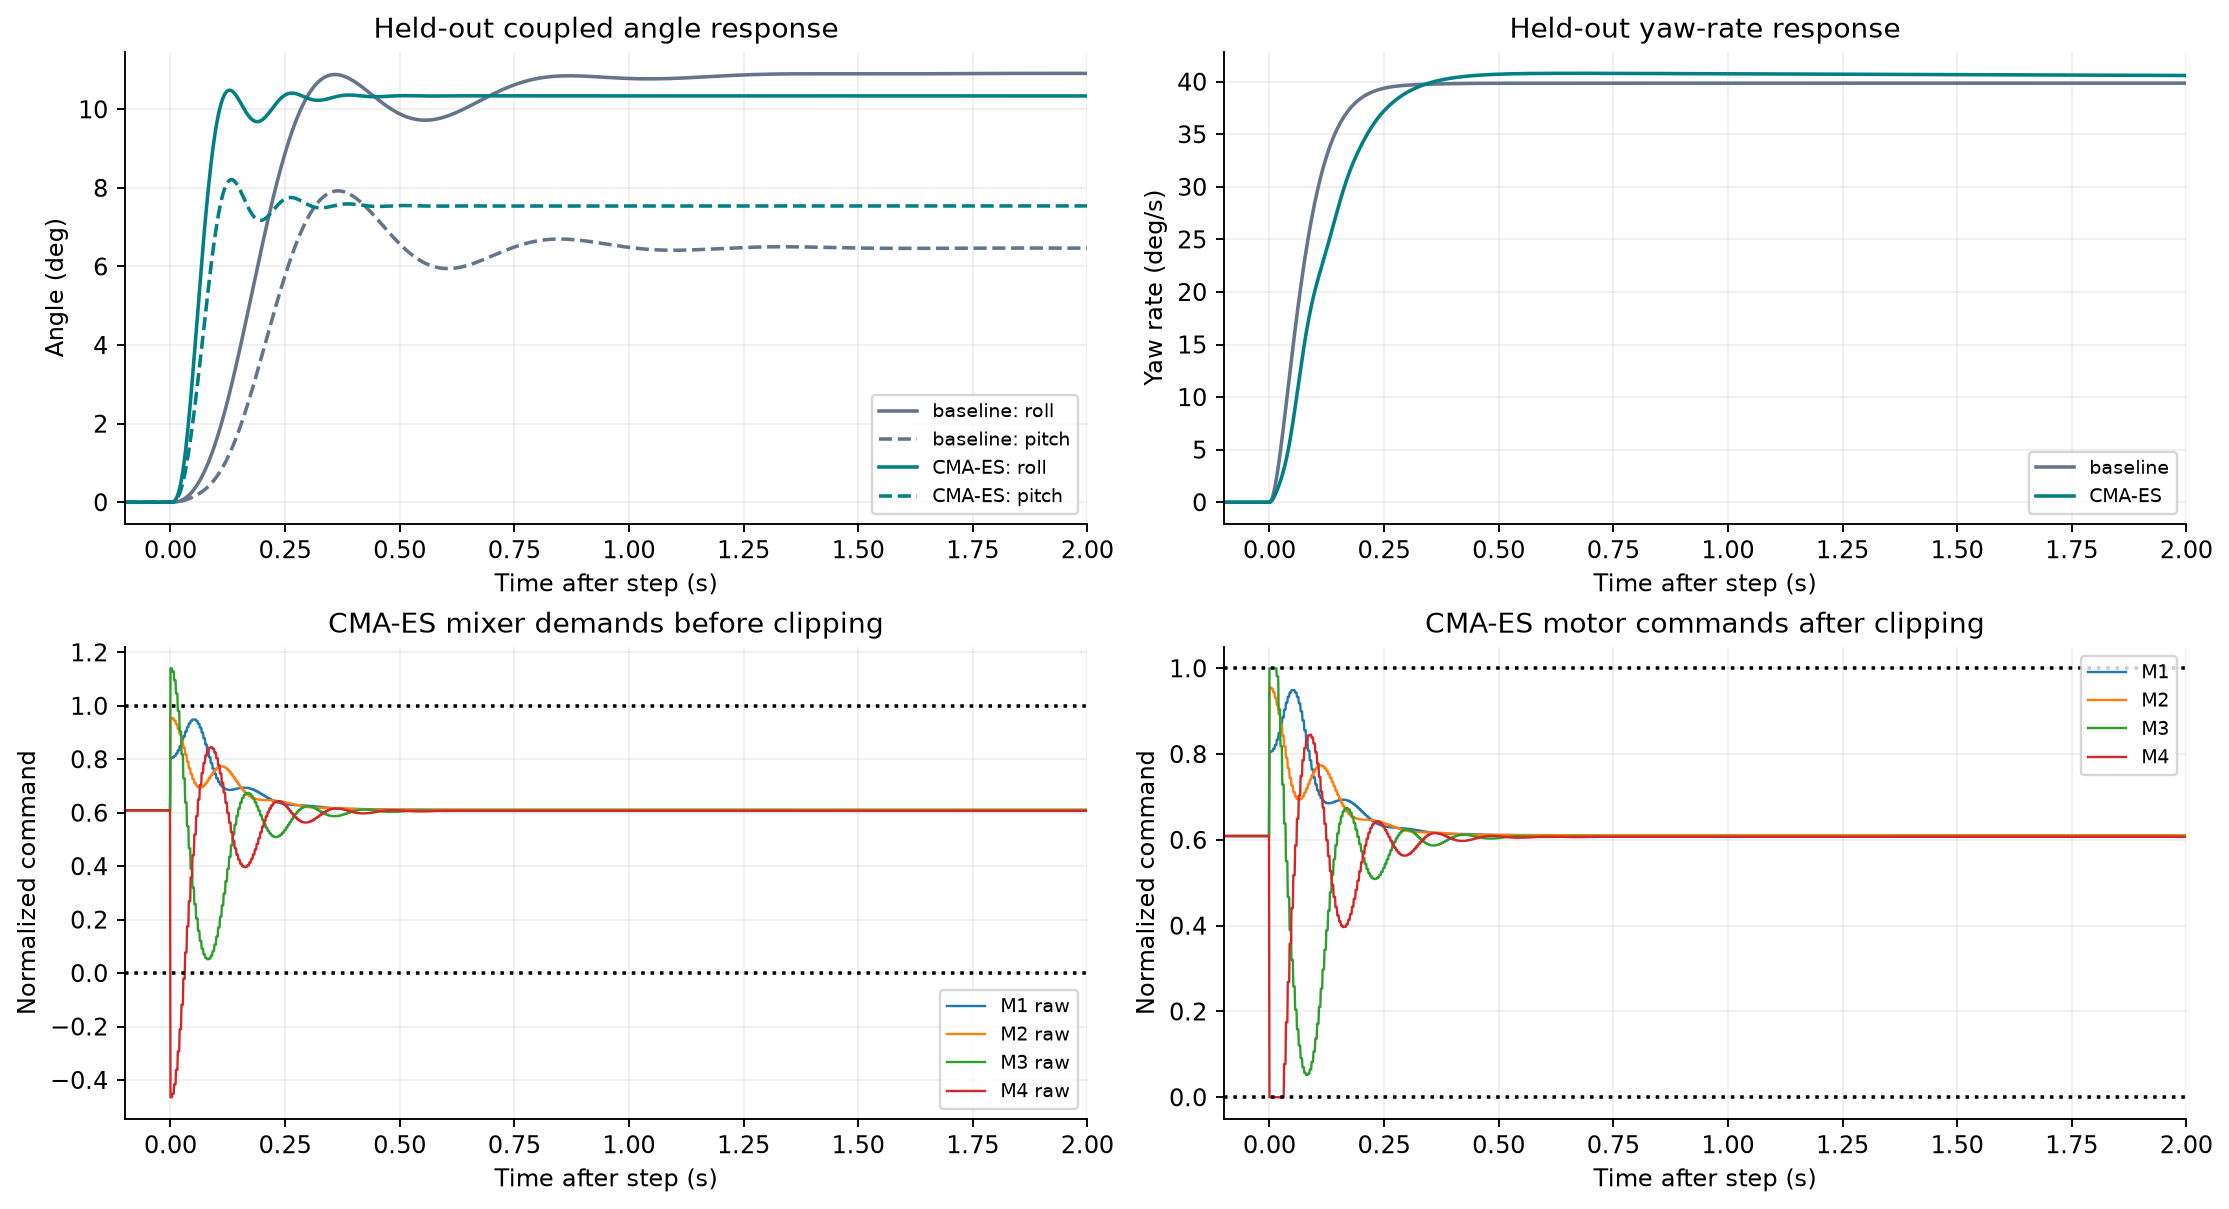

### All saved method figures
- [all work/pid using cma es/results/plots/01_step_responses.png](../all%20work/pid%20using%20cma%20es/results/plots/01_step_responses.png)
- [all work/pid using cma es/results/plots/02_cmaes_iterations.png](../all%20work/pid%20using%20cma%20es/results/plots/02_cmaes_iterations.png)
- [all work/pid using cma es/results/plots/03_coupled_and_saturation.png](../all%20work/pid%20using%20cma%20es/results/plots/03_coupled_and_saturation.png)
- [all work/pid using cma es/results/plots/04_inner_loops.png](../all%20work/pid%20using%20cma%20es/results/plots/04_inner_loops.png)
- [all work/pid using cma es/results/plots/05_robustness.png](../all%20work/pid%20using%20cma%20es/results/plots/05_robustness.png)
- [all work/pid using cma es/results/plots/06_gain_sensitivity.png](../all%20work/pid%20using%20cma%20es/results/plots/06_gain_sensitivity.png)
- [all work/pid using cma es/results/plots/07_metric_comparison.png](../all%20work/pid%20using%20cma%20es/results/plots/07_metric_comparison.png)
- [all work/pid using cma es/results/plots/08_fitness_components.png](../all%20work/pid%20using%20cma%20es/results/plots/08_fitness_components.png)
- [all work/pid using cma es/results/plots/09_robust_candidate.png](../all%20work/pid%20using%20cma%20es/results/plots/09_robust_candidate.png)
- [all work/pid using cma es/results/plots/10_method_responses.png](../all%20work/pid%20using%20cma%20es/results/plots/10_method_responses.png)
- [all work/pid using cma es/results/plots/11_evaluation_comparison.png](../all%20work/pid%20using%20cma%20es/results/plots/11_evaluation_comparison.png)
- [all work/pid using cma es/results/plots/12_cma_adaptation.png](../all%20work/pid%20using%20cma%20es/results/plots/12_cma_adaptation.png)

In [8]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [9]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from cmaes import cma_es
cfg.update(population=8,swarm_size=8,generations=2,iterations=2,workers=1)
result=cma_es(cfg,training_scenarios(),2026,out)
print('Fresh small-search fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../all%20work/pid%20using%20cma%20es/README.md) · [Data checks](../docs/DATA.md)
